# Математический анализ для ML — домашнее задание

**Автор:** _имя_ · **Модуль:** математика для ML, тема 2

Как устроено каждое задание:

1. **Аналитически** — расчёт в markdown: формула → подстановка → ответ.
2. **Код** — проверка вычислений в Python (NumPy).
3. **Визуализация** — Matplotlib.
4. **Вывод** — 2–4 предложения своими словами.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt

## 0. Функции

Функции, которые используются в нескольких заданиях.

In [20]:
# функции появятся по ходу заданий
def num_deriv(f, x, h=1e-4):
    """Производная через конечную разность: шагнули чуть вправо и чуть влево, сравнили."""
    return (f(x + h) - f(x - h)) / (2 * h)

def integrate_rect(f, a, b, n):
    """Левые прямоугольники: высота полоски — значение функции на её левом краю."""
    x = np.linspace(a, b, n + 1)[:-1]
    return np.sum(f(x)) * (b - a) / n

def integrate_trap(f, a, b, n):
    """Трапеции: верх полоски — отрезок между значениями на двух краях."""
    x = np.linspace(a, b, n + 1)
    y = f(x)
    return (b - a) / n * (y[0] / 2 + y[1:-1].sum() + y[-1] / 2)

def gradient_descent(grad, start, lr, tol=1e-6, max_steps=1000):
    """Градиентный спуск: шаг против градиента, пока склон не станет плоским."""
    p = np.array(start, dtype=float)
    history = [p.copy()]
    for step in range(max_steps):
        g = grad(p)
        if np.linalg.norm(g) < tol:          # критерий остановки: длина градиента почти 0
            return np.array(history), "сошёлся"
        p = p - lr * g                       # шаг против градиента
        history.append(p.copy())
        if np.linalg.norm(p) > 1e6:          # точка улетела в бесконечность
            return np.array(history), "разошёлся"
    return np.array(history), "не успел"

def taylor_exp(x, n):
    """eˣ ≈ 1 + x + x²/2! + ... — первые n слагаемых."""
    return sum(x**k / math.factorial(k) for k in range(n))

def taylor_sin(x, n):
    """sin x ≈ x − x³/3! + x⁵/5! − ... — первые n слагаемых."""
    return sum((-1)**k * x**(2*k + 1) / math.factorial(2*k + 1) for k in range(n))

## 1. Функция и её производная

Функция $f(x) = x^3 - 3x^2 + 2$.

- найди первую и вторую производные
- найди критические точки и определи, где функция возрастает и убывает
- классифицируй локальные минимум и максимум
- построй на одном рисунке графики $f(x)$ и $f'(x)$
- приближённо вычисли производную через конечную разность и сравни её с аналитическим ответом

f(x)   = x³ − 3x² + 2
f′(x)  = 3x² − 6x          (степень вниз множителем, сама степень −1)
f″(x)  = 6x − 6

Критические точки: f′(x) = 0 → 3x(x − 2) = 0 → x = 0 и x = 2

Где растёт / убывает (подставляем по точке из каждого участка в f′):
x < 0:      f′(−1) = 3 + 6 = 9  > 0  → растёт
0 < x < 2:  f′(1)  = 3 − 6 = −3 < 0  → убывает
x > 2:      f′(3)  = 27 − 18 = 9 > 0 → растёт

Классификация через f″:
x = 0: f″(0) = −6 < 0 → купол → максимум, f(0) = 2
x = 2: f″(2) =  6 > 0 → чаша  → минимум,  f(2) = 8 − 12 + 2 = −2

x = 0: f'(x) = 0, f''(x) = -6 → максимум, f(x) = 2
x = 2: f'(x) = 0, f''(x) = 6 → минимум, f(x) = -2
h = 0.1: f'(1) ≈ -2.990000, точно = -3, ошибка = 1.0e-02
h = 0.01: f'(1) ≈ -2.999900, точно = -3, ошибка = 1.0e-04
h = 0.001: f'(1) ≈ -2.999999, точно = -3, ошибка = 1.0e-06


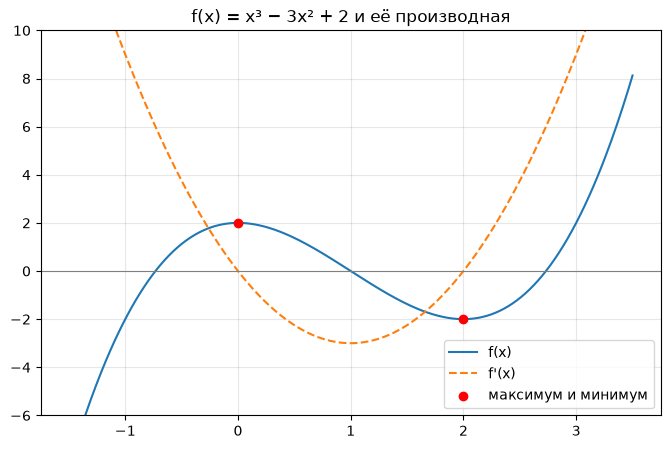

In [5]:
# задание 1
f   = lambda x: x**3 - 3*x**2 + 2        # lambda — короткая запись функции в одну строку
df  = lambda x: 3*x**2 - 6*x
d2f = lambda x: 6*x - 6

for x0 in (0, 2):
    kind = "максимум" if d2f(x0) < 0 else "минимум"
    print(f"x = {x0}: f'(x) = {df(x0)}, f''(x) = {d2f(x0)} → {kind}, f(x) = {f(x0)}")

for h in (0.1, 0.01, 0.001):
    approx = num_deriv(f, 1, h)
    print(f"h = {h}: f'(1) ≈ {approx:.6f}, точно = {df(1)}, ошибка = {abs(approx - df(1)):.1e}")

x = np.linspace(-1.5, 3.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(x, f(x), label="f(x)")
plt.plot(x, df(x), "--", label="f'(x)")
plt.axhline(0, color="gray", lw=0.8)
plt.scatter([0, 2], [f(0), f(2)], color="red", zorder=3, label="максимум и минимум")
plt.ylim(-6, 10); plt.grid(alpha=0.3); plt.legend()
plt.title("f(x) = x³ − 3x² + 2 и её производная")
plt.show()

## 2. Правила дифференцирования

Найди производные функций:

- $f(x) = x^2 \cdot \sin(x)$
- $g(x) = (x^2 + 1)^3$
- $h(x) = e^{2x}$
- $q(x) = \ln(x^2 + 1)$

Для каждой функции укажи, какое правило использовано: произведения, сложной функции или производная элементарной функции. Проверь ответы численно в нескольких точках.

f(x) = x²·sin x       правило произведения: u = x², v = sin x
f′(x) = 2x·sin x + x²·cos x

g(x) = (x² + 1)³      сложная функция: внешняя «куб», внутренняя x² + 1
g′(x) = 3(x² + 1)² · 2x = 6x(x² + 1)²

h(x) = e^(2x)         сложная + элементарная: (eᵘ)′ = eᵘ, внутренняя 2x → 2
h′(x) = e^(2x) · 2 = 2e^(2x)

q(x) = ln(x² + 1)     сложная + элементарная: (ln u)′ = 1/u, внутренняя x² + 1 → 2x
q′(x) = 1/(x² + 1) · 2x = 2x / (x² + 1)

In [6]:
# задание 2
funcs = {
    "f = x²·sin x":  (lambda x: x**2 * np.sin(x),  lambda x: 2*x*np.sin(x) + x**2*np.cos(x)),
    "g = (x²+1)³":   (lambda x: (x**2 + 1)**3,     lambda x: 6*x*(x**2 + 1)**2),
    "h = e^(2x)":    (lambda x: np.exp(2*x),       lambda x: 2*np.exp(2*x)),
    "q = ln(x²+1)":  (lambda x: np.log(x**2 + 1),  lambda x: 2*x / (x**2 + 1)),
}

for name, (fn, dfn) in funcs.items():          # fn — сама функция, dfn — наша формула производной
    for x0 in (-1, 0.5, 2):
        exact, num = dfn(x0), num_deriv(fn, x0)
        print(f"{name:13} x = {x0:4}: формула = {exact:10.5f}, численно = {num:10.5f}, ошибка = {abs(num - exact):.1e}")
    print()

f = x²·sin x  x =   -1: формула =    2.22324, численно =    2.22324, ошибка = 3.9e-09
f = x²·sin x  x =  0.5: формула =    0.69882, численно =    0.69882, ошибка = 6.0e-09
f = x²·sin x  x =    2: формула =    1.97260, численно =    1.97260, ошибка = 2.0e-08

g = (x²+1)³   x =   -1: формула =  -24.00000, численно =  -24.00000, ошибка = 3.2e-07
g = (x²+1)³   x =  0.5: формула =    4.68750, численно =    4.68750, ошибка = 8.5e-08
g = (x²+1)³   x =    2: формула =  300.00000, численно =  300.00000, ошибка = 1.8e-06

h = e^(2x)    x =   -1: формула =    0.27067, численно =    0.27067, ошибка = 1.8e-09
h = e^(2x)    x =  0.5: формула =    5.43656, численно =    5.43656, ошибка = 3.6e-08
h = e^(2x)    x =    2: формула =  109.19630, численно =  109.19630, ошибка = 7.3e-07

q = ln(x²+1)  x =   -1: формула =   -1.00000, численно =   -1.00000, ошибка = 1.7e-09
q = ln(x²+1)  x =  0.5: формула =    0.80000, численно =    0.80000, ошибка = 4.7e-09
q = ln(x²+1)  x =    2: формула =    0.80000, числе

## 3. Пределы и интегралы

- вычисли предел $\frac{\sin x}{x}$ при $x \to 0$ численно для всё меньших значений $x$
- исследуй предел $\frac{e^x - 1}{x}$ при $x \to 0$
- найди аналитически интеграл $f(x) = x^2$ на отрезке $[0, 2]$
- приближённо вычисли тот же интеграл методом прямоугольников и методом трапеций
- сравни ошибку при разном количестве разбиений

Пределы (подставить 0 нельзя — получится 0/0):
sin(x)/x:    0,841 (x=1) → 0,99833 (x=0,1) → 0,9999833 (x=0,01) → ... → 1
(eˣ − 1)/x:  1,718 (x=1) → 1,05171 (x=0,1) → 1,00502   (x=0,01) → ... → 1
Смысл: около нуля sin x ≈ x и eˣ − 1 ≈ x, поэтому отношения стремятся к 1

Интеграл ∫₀² x² dx:
первообразная x³/3  (проверка: (x³/3)′ = 3x²/3 = x²)
= 2³/3 − 0³/3 = 8/3 ≈ 2,6667

x          sin(x)/x       (e^x − 1)/x
1          0.8414709848   1.7182818285
0.1        0.9983341665   1.0517091808
0.01       0.9999833334   1.0050167084
0.001      0.9999998333   1.0005001667
1e-05      1.0000000000   1.0000050000

n =    10: ошибка прямоугольников = 3.87e-01, трапеций = 1.33e-02
n =   100: ошибка прямоугольников = 3.99e-02, трапеций = 1.33e-04
n =  1000: ошибка прямоугольников = 4.00e-03, трапеций = 1.33e-06
n = 10000: ошибка прямоугольников = 4.00e-04, трапеций = 1.33e-08


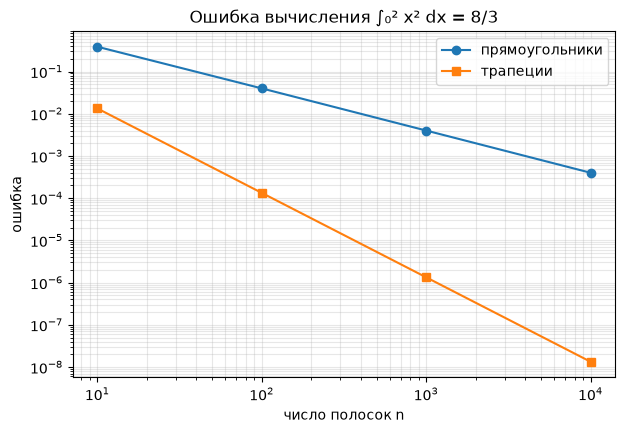

In [9]:
# задание 3
print("x          sin(x)/x       (e^x − 1)/x")
for x in (1, 0.1, 0.01, 0.001, 1e-5):
    print(f"{x:<10} {np.sin(x)/x:.10f}   {(np.exp(x) - 1)/x:.10f}")

sq = lambda x: x**2
exact = 8 / 3
ns = [10, 100, 1000, 10000]
err_rect = [abs(integrate_rect(sq, 0, 2, n) - exact) for n in ns]
err_trap = [abs(integrate_trap(sq, 0, 2, n) - exact) for n in ns]
print()
for n, er, et in zip(ns, err_rect, err_trap):
    print(f"n = {n:5}: ошибка прямоугольников = {er:.2e}, трапеций = {et:.2e}")

plt.figure(figsize=(7, 4.5))
plt.loglog(ns, err_rect, "o-", label="прямоугольники")
plt.loglog(ns, err_trap, "s-", label="трапеции")
plt.xlabel("число полосок n"); plt.ylabel("ошибка")
plt.grid(alpha=0.3, which="both"); plt.legend()
plt.title("Ошибка вычисления ∫₀² x² dx = 8/3")
plt.show()

## 4. Частные производные и градиент

Функция $F(x, y) = x^2 + xy + 2y^2 - 4x + 2y$.

- найди частные производные по $x$ и $y$
- составь вектор градиента и матрицу Гессе
- вычисли градиент в точках $[0, 0]$ и $[2, -1]$
- найди стационарную точку, решив уравнение $\nabla F = 0$
- построй линии уровня функции и отметь на них несколько векторов градиента
- объясни, почему градиент перпендикулярен линии уровня

F = x² + xy + 2y² − 4x + 2y

∂F/∂x (y — константа):  2x + y + 0 − 4 + 0 = 2x + y − 4
∂F/∂y (x — константа):  0 + x + 4y − 0 + 2 = x + 4y + 2

∇F = [2x + y − 4,  x + 4y + 2]

Гессе (производные от производных):
| ∂²F/∂x²   ∂²F/∂x∂y |   =   | 2  1 |
| ∂²F/∂y∂x  ∂²F/∂y²  |       | 1  4 |

∇F(0, 0)  = [0 + 0 − 4,  0 + 0 + 2] = [−4, 2]
∇F(2, −1) = [4 − 1 − 4,  2 − 4 + 2] = [−1, 0]

Стационарная точка ∇F = 0:
2x + y = 4,  x + 4y = −2
из первого y = 4 − 2x  →  x + 4(4 − 2x) = −2  →  −7x = −18
x = 18/7 ≈ 2,571,  y = −8/7 ≈ −1,143
det Гессе = 2·4 − 1·1 = 7 > 0 и 2 > 0 → чаша → минимум

∇F[0, 0] = [-4  2]
∇F[2, -1] = [-1  0]
∂F/∂x численно: -0.9999999999621422 | ∂F/∂y численно: 4.4408920985006255e-11
стационарная точка: [ 2.57142857 -1.14285714] | ∇F в ней: [-4.4408921e-16  0.0000000e+00]
собственные значения Гессе: [1.58578644 4.41421356] → оба > 0, значит минимум


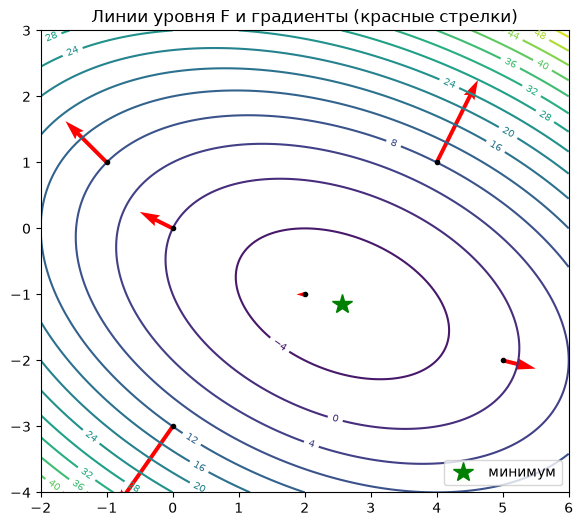

In [12]:
# задание 4
F = lambda x, y: x**2 + x*y + 2*y**2 - 4*x + 2*y
gradF = lambda x, y: np.array([2*x + y - 4, x + 4*y + 2])
H = np.array([[2, 1], [1, 4]])

for p in ([0, 0], [2, -1]):
    print(f"∇F{p} = {gradF(*p)}")

# численная проверка частных производных в точке (2, −1)
h = 1e-5
print("∂F/∂x численно:", (F(2 + h, -1) - F(2 - h, -1)) / (2 * h),
      "| ∂F/∂y численно:", (F(2, -1 + h) - F(2, -1 - h)) / (2 * h))

# стационарная точка: ∇F = 0 — это система 2x + y = 4, x + 4y = −2
stat = np.linalg.solve(np.array([[2, 1], [1, 4]]), np.array([4, -2]))
print("стационарная точка:", stat, "| ∇F в ней:", gradF(*stat))
print("собственные значения Гессе:", np.linalg.eigvalsh(H), "→ оба > 0, значит минимум")

xs, ys = np.meshgrid(np.linspace(-2, 6, 200), np.linspace(-4, 3, 200))
plt.figure(figsize=(7, 6))
cs = plt.contour(xs, ys, F(xs, ys), levels=15, cmap="viridis")
plt.clabel(cs, fontsize=7)
for px, py in [(0, 0), (2, -1), (4, 1), (0, -3), (5, -2), (-1, 1)]:
    g = gradF(px, py)
    plt.quiver(px, py, g[0], g[1], angles="xy", scale_units="xy", scale=8, color="red")
    plt.plot(px, py, "ko", ms=3)
plt.plot(*stat, "g*", ms=15, label="минимум")
plt.gca().set_aspect("equal")                  # без этого прямые углы на графике будут кривыми
plt.legend(); plt.title("Линии уровня F и градиенты (красные стрелки)")
plt.show()

## 5. Градиентный спуск

Минимизируй функцию $G(x, y) = (x - 3)^2 + 2(y + 1)^2$.

- реализуй градиентный спуск без готовых оптимизаторов
- начни из точки $[-4, 5]$ и сохрани историю движения
- сравни learning rate 0.01, 0.1 и 0.8
- построй траекторию оптимизации поверх линий уровня
- объясни, почему слишком большой шаг может мешать сходимости
- добавь критерий остановки по норме градиента

G = (x − 3)² + 2(y + 1)²
∂G/∂x = 2(x − 3),   ∂G/∂y = 2·2(y + 1) = 4(y + 1)     (правило сложной функции)
∇G = 0  →  минимум в точке (3, −1), G = 0

Шаг спуска:  новая точка = точка − lr · ∇G
Старт [−4, 5]:  ∇G = [2·(−7), 4·6] = [−14, 24]
lr = 0.1:  [−4, 5] − 0.1·[−14, 24] = [−4 + 1.4,  5 − 2.4] = [−2.6, 2.6]

Почему lr = 0.8 разлетается (смотрим на y):
(y + 1) после шага = (y + 1) − 0.8·4(y + 1) = (1 − 3.2)(y + 1) = −2.2·(y + 1)
минус — перепрыгнули дно на другой склон, 2.2 — оказались в 2.2 раза дальше
Сходится, только если |1 − 4·lr| < 1  →  lr < 0.5

lr = 0.01: сошёлся за 815 шагов, последняя точка [ 3. -1.]
lr = 0.1: сошёлся за 74 шагов, последняя точка [ 3. -1.]
lr = 0.8: разошёлся за 16 шагов, последняя точка [2.9980000e+00 1.8068159e+06]


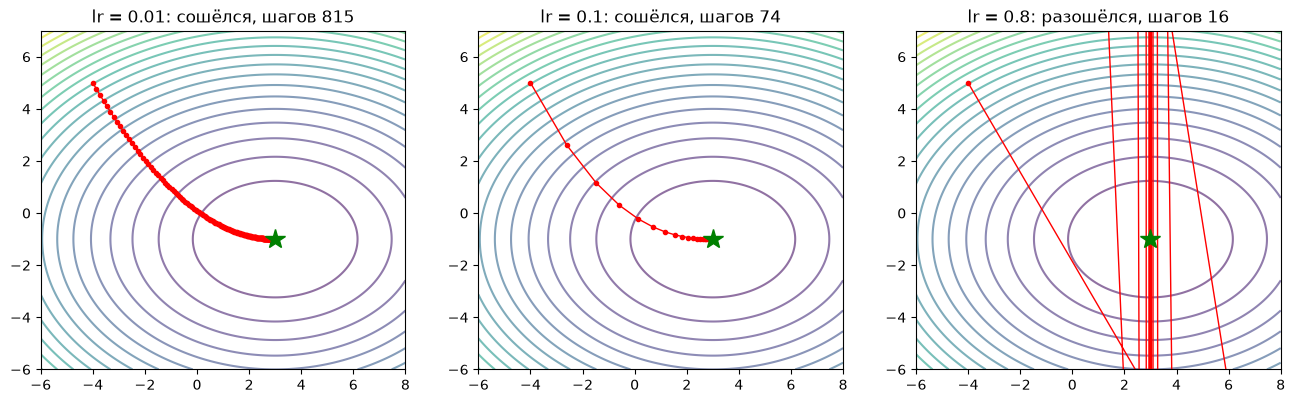

In [15]:
# задание 5
G = lambda x, y: (x - 3)**2 + 2*(y + 1)**2
gradG = lambda p: np.array([2*(p[0] - 3), 4*(p[1] + 1)])

xs, ys = np.meshgrid(np.linspace(-6, 8, 200), np.linspace(-6, 7, 200))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, lr in zip(axes, (0.01, 0.1, 0.8)):
    hist, status = gradient_descent(gradG, [-4, 5], lr)
    print(f"lr = {lr}: {status} за {len(hist) - 1} шагов, последняя точка {np.round(hist[-1], 4)}")
    ax.contour(xs, ys, G(xs, ys), levels=20, cmap="viridis", alpha=0.6)
    ax.plot(hist[:, 0], hist[:, 1], "o-", color="red", ms=3, lw=1)
    ax.plot(3, -1, "g*", ms=15)
    ax.set_xlim(-6, 8); ax.set_ylim(-6, 7); ax.set_aspect("equal")
    ax.set_title(f"lr = {lr}: {status}, шагов {len(hist) - 1}")
plt.show()

## 6. Ряд Тейлора

- реализуй приближение $e^x$ рядом Тейлора в точке 0
- сравни приближения из 1, 2, 5 и 10 слагаемых на отрезке $[-2, 2]$
- построй точную функцию и все приближения на одном графике
- посчитай максимальную ошибку каждого приближения
- повтори эксперимент для $\sin x$
- сформулируй вывод о связи количества слагаемых, области значений и точности

Ряд Тейлора в точке 0 (k! = 1·2·…·k, например 4! = 24):
eˣ    ≈ 1 + x + x²/2! + x³/3! + x⁴/4! + ...
sin x ≈ x − x³/3! + x⁵/5! − x⁷/7! + ...

Откуда коэффициенты: все производные eˣ в нуле равны 1,
каждое слагаемое = (k-я производная в нуле) · xᵏ / k!

Пример: e¹ из 5 слагаемых = 1 + 1 + 1/2 + 1/6 + 1/24 = 2,7083   (точно e = 2,7183)

eˣ     n =  1: макс. ошибка на [−2, 2] = 6.39e+00
eˣ     n =  2: макс. ошибка на [−2, 2] = 4.39e+00
eˣ     n =  5: макс. ошибка на [−2, 2] = 3.89e-01
eˣ     n = 10: макс. ошибка на [−2, 2] = 3.44e-04

sin x  n =  1: макс. ошибка на [−2, 2] = 1.09e+00
sin x  n =  2: макс. ошибка на [−2, 2] = 2.43e-01
sin x  n =  5: макс. ошибка на [−2, 2] = 5.00e-05
sin x  n = 10: макс. ошибка на [−2, 2] = 4.07e-14

eˣ, 5 слагаемых, x = 0.5: ошибка = 2.84e-04
eˣ, 5 слагаемых, x = 1: ошибка = 9.95e-03
eˣ, 5 слагаемых, x = 2: ошибка = 3.89e-01


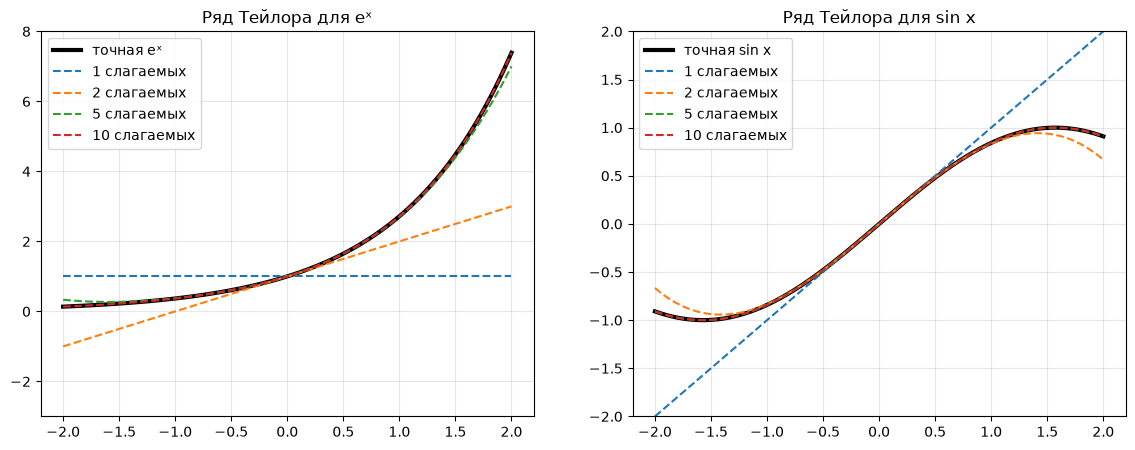

In [21]:
# задание 6
x = np.linspace(-2, 2, 400)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cases = [("eˣ", np.exp, taylor_exp, (-3, 8)), ("sin x", np.sin, taylor_sin, (-2, 2))]

for ax, (name, exact, approx, ylim) in zip(axes, cases):
    ax.plot(x, exact(x), "k", lw=3, label=f"точная {name}")
    for n in (1, 2, 5, 10):
        y = approx(x, n)
        err = np.max(np.abs(y - exact(x)))
        print(f"{name:6} n = {n:2}: макс. ошибка на [−2, 2] = {err:.2e}")
        ax.plot(x, y, "--", label=f"{n} слагаемых")
    ax.set_ylim(*ylim); ax.grid(alpha=0.3); ax.legend()
    ax.set_title(f"Ряд Тейлора для {name}")
    print()

# точность зависит от расстояния до нуля
for x0 in (0.5, 1, 2):
    print(f"eˣ, 5 слагаемых, x = {x0}: ошибка = {abs(taylor_exp(x0, 5) - np.exp(x0)):.2e}")
plt.show()

## 7. Как это связано с обучением моделей ML

_Своими словами: как производная, градиент и градиентный спуск используются при обучении моделей._

...

Модель — это функция с весами (у нейросетей их миллионы). Ошибка модели
на данных (loss) — функция от весов, «рельеф», как G(x, y) в задании 5,
только размерностей не 2, а миллионы. Обучение — поиск дна этого рельефа.

- Производная (задание 1) показывает, как изменится ошибка, если чуть сдвинуть
  один вес. f′ = 0 — дно, дальше двигаться некуда.
- Правило сложной функции (задание 2) — это backpropagation: нейросеть —
  цепочка функций-слоёв, и градиент считается по этой цепочке слой за слоем.
- Градиент (задание 4) собирает производные по всем весам в один вектор
  и показывает, куда ошибка растёт быстрее всего.
- Градиентный спуск (задание 5): веса = веса − lr · ∇loss, повторять,
  пока ошибка не перестанет падать.
- Learning rate решает всё: при lr = 0.01 спуск шёл 815 шагов, при 0.1 — 74,
  а при 0.8 точка улетела. В реальном обучении так же: маленький шаг — долго,
  большой — loss «взрывается».
- Ряд Тейлора (задание 6) объясняет, почему шаг должен быть маленьким:
  градиент верно описывает функцию только рядом с текущей точкой.
- Ловушка из задания 1: минимум f в x = 2 локальный, левее функция уходит
  ещё ниже. Градиентный спуск тоже может застрять в такой ямке.

## Перед сдачей

- [ ] `Restart & Run All` проходит без ошибок
- [ ] у каждого задания есть: аналитика → код → график (где нужно) → вывод
- [ ] выводы написаны своими словами